# scLATCH: dynamic gene regulatory networks, end to end

scLATCH is a conditional denoising diffusion model whose denoiser embeds a learnable gene by
gene adjacency A; the converged A is the inferred GRN. A low-rank, pseudotime- and
condition-gated term gives a dynamic network A(tau, k). This notebook runs the whole pipeline
and every analysis, and generalizes to any dataset through the config cell below.

The defaults run offline on the bundled quick-run copy of huang_tcell (Fig 4 CD8 T-cell
exhaustion multiome): `data/huang_tcell/` has 1200 cells (400 per condition, fixed seed), all
21,731 genes kept, and the precomputed real paper mask. It is a labeled subsample for a fast
run, not the paper run. For the exact paper numbers, download the full dataset and re-run.


## 0. Config and formulation

Edit these four variables to run on your own data. `DATASET_NAME` is the folder under `data/`;
`CONDITION_KEY` is the column in `metadata.csv` that holds the experimental conditions;
`ROOT_GENE` is a marker of the least-differentiated (progenitor / stem) state used to set the
pseudotime root; `CANDIDATE_ROOTS` are markers to inspect when picking a root.


In [1]:
# ===================== EDIT ME for your dataset =====================
DATASET_NAME    = "huang_tcell"     # folder under data/
ORGANISM        = "mouse"           # "human" or "mouse"
CONDITION_KEY   = "condition"       # column in metadata.csv holding the conditions
ROOT_GENE       = "Tcf7"            # marker of the least-differentiated state (pseudotime root)
CANDIDATE_ROOTS = ["Tcf7", "Il7r", "Sell", "Lef1", "Ccr7"]   # candidates to inspect
# ====================================================================

**No-condition (pseudotime-only) mode.** If you set `CONDITION_KEY = None`, or your
`metadata.csv` has no condition column, scLATCH trains pseudotime-only A(tau): the dynamic gate
uses pseudotime but no categorical condition, and `model.conditions()` returns an empty list.
All the tau-dynamics still apply: static and tau-only networks, `reconfiguration_curve`,
`commitment_boundary`, `gene_strength_heatmap`, `network_snapshots`, `edge_trajectory`,
`knockout`, `quasi_potential`, and `save_results` (which writes STATIC plus tau-only DYNAMIC
files and skips the condition-specific ones with a note). Compare two pseudotimes with
`top_changing_edges(tau_a=..., tau_b=...)`. The condition-only analyses (`delta_S`,
`plot_differential_network` between conditions, and the Section 6 condition showcase) need at
least two conditions and raise a clear error otherwise. This notebook uses huang_tcell, which
has conditions; a full pseudotime-only worked example on PBMC is provided as a separate
notebook.


In [2]:
# Quiet the cosmetic warnings so the notebook output stays clean (no venv paths, no NVML).
import warnings, os
warnings.filterwarnings("ignore")
os.environ.setdefault("PYTHONWARNINGS", "ignore")
import numpy as np
np.seterr(all="ignore")
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")            # run from the repo root so data/ and priors/ resolve

**How scLATCH is formulated.** Expression is library-size + log1p normalized, then the
model applies per-cell min-max and per-gene z-score. Gaussian noise is added
($x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon$, linear $\beta$, $T=5000$) and the
denoiser predicts $\epsilon$. A condition vector sums three L2-normalized embeddings of
diffusion time $t$, pseudotime $\tau$, and the categorical condition $k$. Per-gene embeddings
are mixed by $(I-A)$ at the output, so the static adjacency
$A_{\mathrm{static}}=\mathrm{sign}(W)\,\mathrm{relu}(|W|-\tau_{\mathrm{thr}})$ (masked, diagonal
zeroed) is the network. The dynamic network is
$A(\tau,k)=A_{\mathrm{static}}+U\,\mathrm{diag}(\mathrm{gate}(c))\,V$, rank 32.

**scLATCH is multiome.** The per-cell model input is RNA. The regulatory **mask** requires
chromatin accessibility from scATAC: ChIP-Atlas binding within 10 kb of the TSS intersected
with accessible ATAC peaks over a curated TF list (`priors/README.md`), applied softly as
$M_{\mathrm{eff}}=M+0.4(1-M)$. ATAC does not enter the network directly; it is used upstream to
build the mask.


## 1. Setup

Install a GPU build of PyTorch first, then `pip install -e ".[viz]"` (see Install in the
README; check `torch.cuda.is_available()`). Put your dataset in `data/<DATASET_NAME>/` (see
`data/README.md`): `expression.h5ad` (raw counts in `.X` or a `counts` layer),
`metadata.csv` (index = cell barcode, a `CONDITION_KEY` column with your condition labels),
`atac.h5ad` (scATAC for the mask, or use a reference atlas), optional `ground_truth.csv`. Put
priors in `priors/` (TF lists and TSS tables ship; download the ChIP-Atlas cache only to rebuild
masks). The bundled huang_tcell needs no downloads.


## 2. Load, choose the pseudotime root, and preprocess

`preprocess` normalizes, builds the kNN graph, and computes diffusion pseudotime from a root
cell (pseudotime `tau = 0`).

**Two ways to set the root.**
- **Default (`root_gene=None`):** the pipeline picks the root automatically. If you pass
  `root_cell_type`, it takes that cell type at the diffusion-component-1 extreme; otherwise it
  uses a gene-count (CytoTRACE-style) heuristic that assumes the most transcriptionally active
  cell is the least differentiated, and prints a warning. It then validates the direction and
  inverts `tau` if needed. The risk: the automatic root can pick the wrong end and leans on the
  inversion to fix it, so it is less reliable.
- **Provide `root_gene` (recommended):** pass a marker of the least-differentiated
  (progenitor / stem / naive) state. The root is the cell with the highest expression of that
  marker, and the direction is validated so the marker DECREASES along `tau`.

**Picking the root gene from your own data.** Choose a known marker of the least-differentiated
state for your system, then verify it: it should be highest in the putative starting state and
decrease along the trajectory. The cell below shows a few candidate markers averaged per
condition, so you can see which one marks the start.


In [3]:
import sclatch, pandas as pd, matplotlib.pyplot as plt

ds = sclatch.load_dataset(DATASET_NAME, organism=ORGANISM)

# Candidate-marker table: mean log1p expression per condition (generic; uses CONDITION_KEY).
def marker_table(adata, genes, cond_series):
    X = adata.layers["counts"] if "counts" in adata.layers else adata.X
    out = {}
    for g in genes:
        if g not in adata.var_names:
            continue
        col = X[:, adata.var_names.get_loc(g)]
        col = col.toarray().ravel() if hasattr(col, "toarray") else np.asarray(col).ravel()
        col = np.log1p(col)
        out[g] = {c: float(col[cond_series.values == c].mean()) for c in cond_series.unique()}
    return pd.DataFrame(out).T

group_key = CONDITION_KEY if (CONDITION_KEY and CONDITION_KEY in ds.metadata.columns) else "cell_type"
mt = marker_table(ds.adata, CANDIDATE_ROOTS, ds.metadata[group_key])
print(f"mean log1p expression per {group_key} (pick the marker highest in the start group):")
print(mt.round(3))

mean log1p expression per condition (pick the marker highest in the start group):
      naive  exhausted_wt  tox_ko
Tcf7  0.904         0.470   0.626
Il7r  1.060         0.163   0.256
Sell  0.875         0.057   0.077
Lef1  1.688         0.252   0.321
Ccr7  0.369         0.022   0.022


On huang, `Tcf7` (a stem/naive marker) is highest in the naive population, so it marks
the least-differentiated state and is the correct root. Set `ROOT_GENE` to the marker that is
highest in your start state, then preprocess.


In [4]:
ds = sclatch.preprocess(ds, root_gene=ROOT_GENE, organism=ORGANISM)

**Direction check.** The final pseudotime must have the root gene DECREASING along `tau`
(Spearman `rho < 0`). The pipeline flips `tau` to `1 - tau` if the root gene increases along it,
so the trajectory runs from the least-differentiated state outward. The cell below prints the
final root-gene-vs-tau correlation; it must be negative (correctly directed).


In [5]:
from scipy.stats import spearmanr
X = ds.adata[:, ROOT_GENE].X
expr = X.toarray().ravel() if hasattr(X, "toarray") else np.asarray(X).ravel()
m = expr > 0
rho, _ = spearmanr(ds.pseudotime[m], expr[m])
verdict = "correctly directed (decreases along tau)" if rho < 0 else "WRONG: increases along tau"
print(f"{ROOT_GENE} vs pseudotime  Spearman rho = {rho:+.3f}  ->  {verdict}")

Tcf7 vs pseudotime  Spearman rho = -0.203  ->  correctly directed (decreases along tau)


## 3. Build the prior (mask)

The bundled data ships the precomputed real paper mask, so `build_prior` loads it offline with
no download.


In [6]:
mask = sclatch.build_prior(ds, organism=ORGANISM)   # loads the bundled precomputed mask (offline)
mask.shape

(21731, 21731)

**Rebuild from your own scATAC (optional; needs the ChIP-Atlas cache).** With the full
dataset's `atac.h5ad` in `data/<DATASET_NAME>/` and the ChIP-Atlas cache in
`priors/chip_atlas/<genome>/`, `build_prior(ds, rebuild=True)` builds the mask from
accessibility and prints each step. On the full huang_tcell:

```
accessibility: own scATAC (data/huang_tcell/atac.h5ad)
  Accessible peaks (>1% cells): 130867/247460
  Genes with nearby peaks: 9756/21731
  ChIP-Atlas (mm10): 425/1375 TFs with binding, 920542 edges
```

which reproduces the precomputed paper mask. A cohort with no matched ATAC passes
`reference_atac=<path>` (Fig 7 used the Satpathy TIL scATAC atlas, GSE129785). Order of
preference: own scATAC, then a reference atlas, then mask-free (`train(ds, mask=None)`, RNA-only
de-novo at expression-baseline level, a last-resort fallback that no benchmark uses).

**Recompute (shown below).** The committed output of the next cell shows the full mask
recomputation: ChIP-Atlas TF binding within 10 kb of the TSS, intersected with accessible
scATAC peaks, over the pySCENIC mouse TF list, plus the overlap with the bundled precomputed
mask. The bundled huang_tcell mask was built with that list, so the rebuild passes
`tf_list="pyscenic"`, and `allow_download=False` keeps it on the local ChIP-Atlas cache. It
runs when the ChIP-Atlas cache (`priors/chip_atlas/<genome>/`) and the dataset scATAC
(`data/<DATASET_NAME>/atac.h5ad`) are present. A fresh clone without those downloads skips it
(the guard) and uses the bundled precomputed mask, so the offline run stays 0-error.


In [7]:
# Recompute the mask from raw inputs to SHOW the full calculation. Guarded so a bare
# offline clone (no ChIP-Atlas cache, no atac.h5ad) still runs: it prints the fallback line.
# Recompute reads the TF list and TSS from priors/, the ChIP-Atlas cache from
# priors/chip_atlas/<genome>/, and the dataset's own scATAC from data/<DATASET_NAME>/atac.h5ad.
import glob
from scipy.sparse import load_npz, csr_matrix
_genome = {"mouse": "mm10", "human": "hg38"}[ORGANISM]
_have_cache = bool(glob.glob(f"priors/chip_atlas/{_genome}/*.tsv"))
_have_atac  = os.path.exists(f"data/{DATASET_NAME}/atac.h5ad")
if _have_cache and _have_atac:
    # the bundled huang_tcell mask was built with the pySCENIC mouse TF list
    mask_rebuilt = sclatch.build_prior(ds, organism=ORGANISM, rebuild=True,
                                       tf_list="pyscenic", allow_download=False)
    _rb = csr_matrix(mask_rebuilt > 0)                             # sparse bool (few edges)
    _bd = (load_npz(f"data/{DATASET_NAME}/atac_mask.npz") > 0)     # bundled, sparse bool
    _nr, _nb = int(_rb.nnz), int(_bd.nnz)
    _inter = int(_rb.multiply(_bd).nnz); _union = _nr + _nb - _inter
    print(f"recomputed edges = {_nr:,} | bundled edges = {_nb:,} | "
          f"Jaccard = {_inter/_union:.3f} | recall(bundled) = {_inter/_nb:.3f}")
else:
    print(f"recompute skipped (offline default): needs data/{DATASET_NAME}/atac.h5ad and "
          f"priors/chip_atlas/{_genome}/*.tsv (see priors/README.md); using the bundled mask.")

  Building ATAC mask: 21731 genes, mouse (mm10)


  TF list: 1375 TFs (pySCENIC mouse, mm_mgi_tfs.txt, 1721 total, 21731 genes in dataset)


  [Step 1] Getting TSS positions...


  Loading TSS from local file priors/tss/mm10_gene_tss.csv (offline)...


    TSS mapped from file: 20610/21731


...

    Edges:      920,542 (0.195%)


    TFs:        425


    Targets:    7389


    Saved: outputs/masks/huang_tcell/atac_mask.npz (0.5 MB, was 1889 MB dense)


recomputed edges = 920,542 | bundled edges = 917,427 | Jaccard = 0.958 | recall(bundled) = 0.980


## 4. Train with the exact paper configuration

`train` runs the canonical trainer with `FINAL_DYNAMIC_CONFIG` and `CONDITION_KEY` as the
categorical covariate, so the learned network is A(tau, k). Training is device-aware: it uses a
CUDA GPU when one is available and falls back to CPU otherwise (a GPU is recommended for this
step; CPU works but is slower). All outputs are repo-relative (`runs/`, `outputs/`). Set
`TRAIN_FROM_SCRATCH = False` to load a released checkpoint instead; both give the same
`TrainedModel`.


In [8]:
from sclatch.training import FINAL_DYNAMIC_CONFIG
FINAL_DYNAMIC_CONFIG

{'continuous': ['pseudotime'],
 'atac_mask': True,
 'mask_leak': 0.4,
 'no_mask_anneal': True,
 'hidden_dims': [16, 16, 16],
 'cond_dim': 64,
 'adj_dropout': 0.3,
 'sparse_threshold_coef': 0.2,
 'dynamic_rank': 32,
 'lambda_temporal': 0.05,
 'T': 5000,
 'n_steps': 2000,
 'batch_size': 256,
 'lr_nn': 0.001,
 'lr_adj_divisor': 50,
 'wd_nn': 0.1,
 'wd_adj': 0.01,
 'sparse_coef': 0.025}

In [9]:
TRAIN_FROM_SCRATCH = True   # False -> sclatch.load_model("runs/.../model.pt", dataset=ds)

if TRAIN_FROM_SCRATCH:
    model = sclatch.train(ds, mask, condition_key=CONDITION_KEY)
else:
    model = sclatch.load_model(f"runs/{DATASET_NAME}/dynamic/model.pt", dataset=ds,
                               condition_key=CONDITION_KEY)
conditions = model.conditions()   # read from the data, not hardcoded
print("conditions:", conditions)

  Expression: 1200 cells × 21731 genes



--- Seed 42 ---


  training:   0%|                                             | 0/2000 [00:00<?]


  training:   2%|▊                                       | 43/2000 [00:20<15:14]


  training:   4%|▋                | 85/2000 [00:40<15:08, loss=1.0987 adj_Δ=inf]


  training:   6%|▋          | 127/2000 [01:00<14:54, loss=0.7082 adj_Δ=0.000048]


  training:   8%|▉          | 169/2000 [01:20<14:41, loss=0.2349 adj_Δ=0.000005]


  training:  10%|█         | 210/2000 [01:40<14:26, loss=-0.0926 adj_Δ=0.000002]



conditions: ['exhausted_wt', 'naive', 'tox_ko']


## 5. Analyses

Each analysis is a method on the trained model, returning values and a focused `.plot()`.
Conditions come from `model.conditions()`, so they follow your `CONDITION_KEY`.


### 5.1 Static network. $A_{\mathrm{static}}$; per-TF out-strength $S_j=\sum_i|A[i,j]|$.

strongest regulators: ['Spi1', 'Usf2', 'Dr1', 'Kdm4c', 'Nfib', 'Insm1', 'Ets1', 'Max']


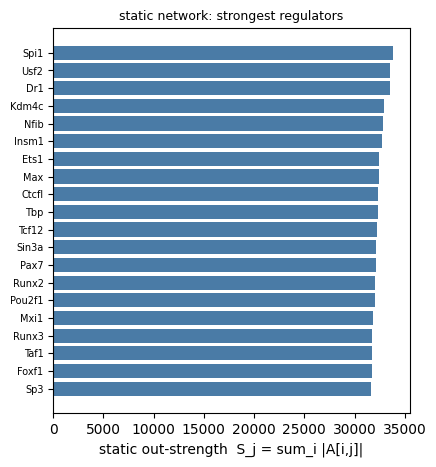

In [10]:
sn = model.static_network(top_n_tfs=20)
print("strongest regulators:", list(sn.top.index[:8]))
fig, ax = plt.subplots(figsize=(4.6, 5)); sn.plot(ax); plt.show()

### 5.2 Dynamic network. $A(\tau,k)$ at a chosen state, shown as an interpretable GRN
graph via `plot_network` (TF hubs, edge width $=|weight|$, color $=$ sign). Large hubs are TFs
that regulate many targets in that state; thick edges are the strongest interactions. The
condition is user-supplied (here the first condition read from the data).

A(tau=0.5, exhausted_wt): (21731, 21731)


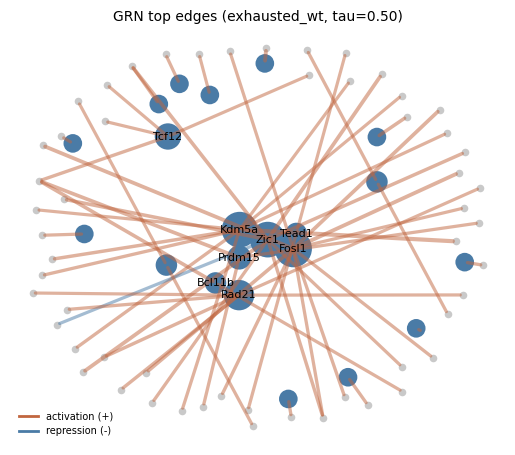

In [11]:
cond0 = conditions[0] if conditions else None
dyn = model.dynamic_network(pseudotime=0.5, condition=cond0)
print("A(tau=0.5, %s):" % cond0, dyn.adjacency.shape)
fig, ax = plt.subplots(figsize=(6.4, 5.4))
model.plot_network(condition=cond0, pseudotime=0.5, top_n_edges=60, ax=ax); plt.show()

### 5.3 Regulatory output. $S_j=\sum_i|A(\tau,k)[i,j]|$ at the mean pseudotime of the
condition.

top regulators (exhausted_wt): ['Zic1', 'Fosl1', 'Kdm5a', 'Nfib', 'Tbp', 'Taf1', 'Phf8', 'Tcf12']


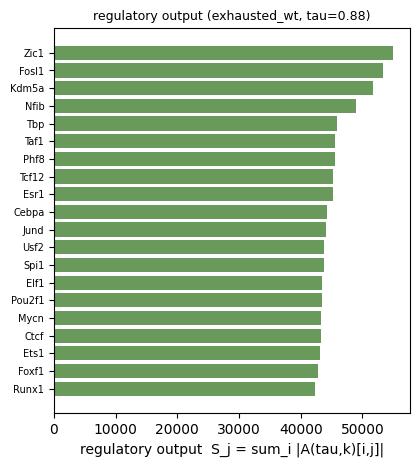

In [12]:
ro = model.regulatory_output(condition=cond0, top_n=20)
print("top regulators (%s):" % cond0, list(ro.top.index[:8]))
fig, ax = plt.subplots(figsize=(4.6, 5)); ro.plot(ax); plt.show()

### 5.4 Reconfiguration curve. $\|A(\tau)-A(0)\|_F$ across pseudotime.

max rewiring: 5.382


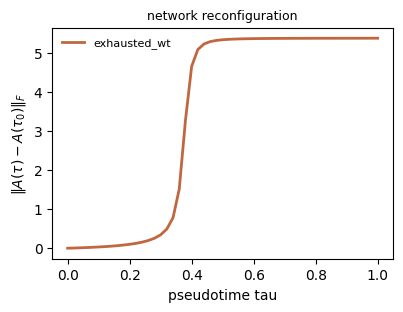

In [13]:
rc = model.reconfiguration_curve(condition=cond0)
print("max rewiring:", round(float(rc.frob.max()), 3))
fig, ax = plt.subplots(figsize=(4.4, 3)); rc.plot(ax); plt.show()

### 5.5 Commitment boundary. $\arg\max_\tau|\tfrac{d}{d\tau}\|A(\tau)-A(0)\|_F|$.

commitment boundary tau = 0.38


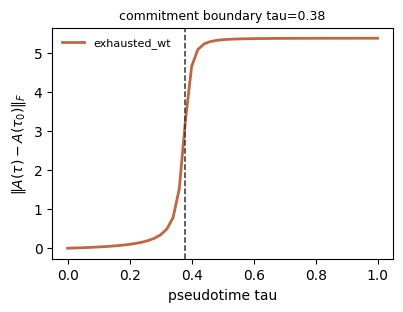

In [14]:
cb = model.commitment_boundary(condition=cond0)
print("commitment boundary tau =", round(cb.boundary, 3))
fig, ax = plt.subplots(figsize=(4.4, 3)); cb.plot(ax); plt.show()

### 5.6 In-silico knockout. Pure in-silico from the trained network (no external
perturbation data). Accepts one TF or a list; direct signature $=-\sum_{\mathrm{TF}}A[:,\mathrm{TF}]$.

knockout Spi1 top responders: ['Rfxap', 'Pprc1', 'Anp32b', 'Tmem217', 'Map4k4', 'Ccr3'] | removed edges: (200, 4)


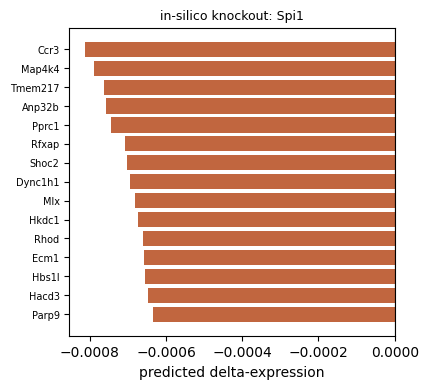

In [15]:
ko_tf = sn.top.index[0]   # a strong regulator, generic
ko = model.knockout(ko_tf, condition=cond0, top_n=15, return_network=True)
print("knockout", ko_tf, "top responders:", list(ko.top.index[-6:]), "| removed edges:", ko.removed_edges.shape)
fig, ax = plt.subplots(figsize=(4.2, 4)); ko.plot(ax); plt.show()

### 5.7 Quasi-potential landscape. $U(s)=-\log\rho(s)$ of a network-state coordinate.

U range: 0.0 to 7.93


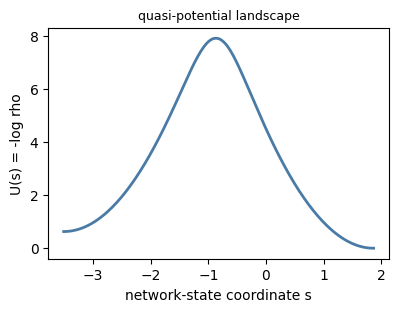

In [16]:
qp = model.quasi_potential(condition=cond0)
print("U range:", round(float(qp.potential.min()), 2), "to", round(float(qp.potential.max()), 2))
fig, ax = plt.subplots(figsize=(4.4, 3)); qp.plot(ax); plt.show()

### 5.8 Gene-by-tau strength heatmap. $S_j(\tau)$ per TF across pseudotime.

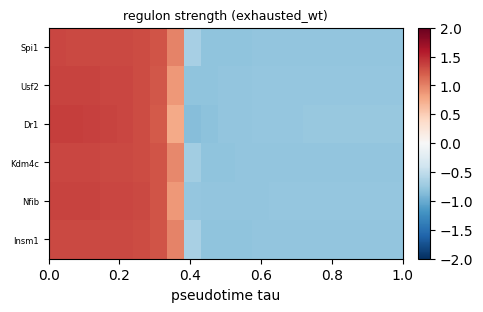

In [17]:
gh = model.gene_strength_heatmap(tfs=list(sn.top.index[:6]), condition=cond0)
fig, ax = plt.subplots(figsize=(5, 3)); gh.plot(ax); plt.show()

## 6. Condition showcase

The condition enters only through the condition vector, so A(tau, k), $S_j(k)$, and $\Delta S$
are read out per condition. Conditions are read from the data via `model.conditions()`; nothing
is hardcoded.


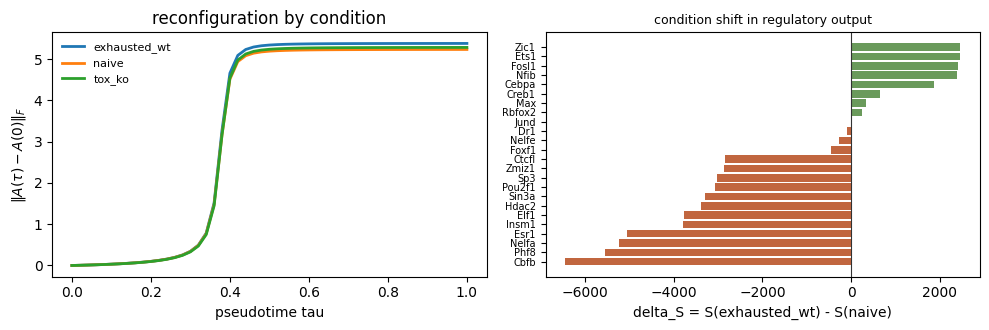

exhausted_wt vs naive: most down-weighted: ['Cbfb', 'Phf8', 'Nelfa', 'Esr1', 'Insm1']
exhausted_wt vs naive: most up-weighted  : ['Cebpa', 'Nfib', 'Fosl1', 'Ets1', 'Zic1']


In [18]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for c in conditions:
    rc = model.reconfiguration_curve(condition=c)
    ax[0].plot(rc.tau, rc.frob, lw=2, label=c)
ax[0].set_xlabel("pseudotime tau"); ax[0].set_ylabel(r"$\|A(\tau)-A(0)\|_F$")
ax[0].set_title("reconfiguration by condition"); ax[0].legend(frameon=False, fontsize=8)

a, b = conditions[0], conditions[1]          # first two conditions from the data
dS = model.delta_S(a, b, top_n=12); dS.plot(ax[1])
plt.tight_layout(); plt.show()
print(f"{a} vs {b}: most down-weighted:", list(dS.delta_S.index[:5]))
print(f"{a} vs {b}: most up-weighted  :", list(dS.delta_S.index[-5:]))

## 7. Network changes, tau trajectories, and saving results

Visualize how the network differs between conditions, follow single edges along pseudotime,
and save everything in documented formats.


### 7.1 Differential network between two conditions (gained vs lost edges).

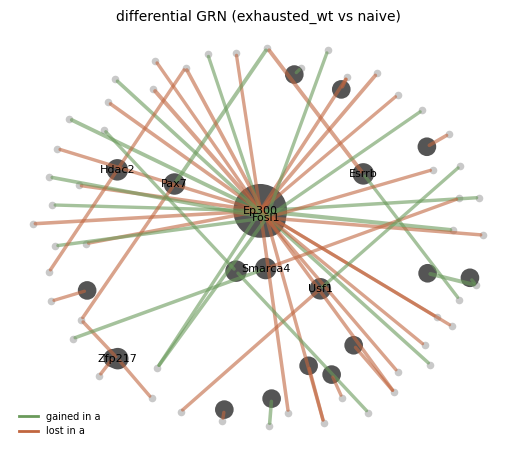

In [19]:
fig, ax = plt.subplots(figsize=(6.4, 5.4))
model.plot_differential_network(cond_a=conditions[0], cond_b=conditions[1],
                                top_n_edges=60, ax=ax); plt.show()

### 7.2 Edge trajectory. A single TF -> target weight across pseudotime. Here we take
the top changing edge between the first two conditions and follow it.

  regulator_TF target_gene  weight_a   weight_b     change
0        Ep300      Ccdc62  6.673285 -33.389076  40.062362
1        Ep300       Pcif1  0.061548  39.132526 -39.070978
2        Sin3a      Mettl8 -6.480756 -43.970490  37.489734
3        Esrrb       Fkbp2  7.583107  44.846771 -37.263665
4         Pax7       Fkbp2  4.531332 -32.604183  37.135515


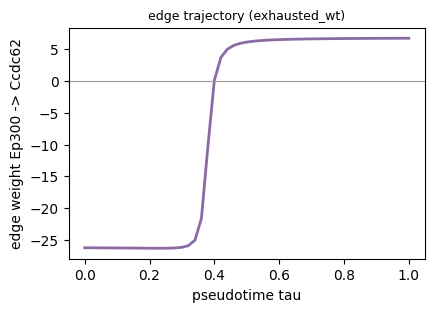

In [20]:
chg = model.top_changing_edges(cond_a=conditions[0], cond_b=conditions[1], top_n=5)
print(chg.head())
tf, target = chg.iloc[0]["regulator_TF"], chg.iloc[0]["target_gene"]
et = model.edge_trajectory(tf, target, condition=conditions[0])
fig, ax = plt.subplots(figsize=(4.6, 3)); et.plot(ax); plt.show()

### 7.3 Network snapshots along tau. A(tau, k) top edges at several pseudotime points.

In [21]:
snaps = model.network_snapshots(tau_grid=[0.1, 0.4, 0.7, 1.0], condition=conditions[0], top_n=200)
for t, df in snaps.items():
    print(f"tau={t}: {len(df)} edges, top: {df.iloc[0]['regulator_TF']} -> {df.iloc[0]['target_gene']}")

tau=0.1: 200 edges, top: Cebpd -> Ckap2l
tau=0.4: 200 edges, top: Cebpb -> Glce
tau=0.7: 200 edges, top: Kdm5a -> U2af1
tau=1.0: 200 edges, top: Kdm5a -> U2af1


### 7.4 Save all results. Writes edge lists, S per condition, delta_S, the
reconfiguration curve, the gate-entropy curve, and snapshots to `outputs/`, with a
`RESULTS_README.md` documenting every file and column.

In [22]:
out_dir = model.save_results(f"outputs/{DATASET_NAME}_results")
print(open(os.path.join(out_dir, "RESULTS_README.md")).read())

saved 11 result files (2 static, 9 dynamic) + RESULTS_README.md -> outputs/huang_tcell_results
# scLATCH results

Trained-network read-outs. Conditions: ['exhausted_wt', 'naive', 'tox_ko']. A[target, regulator]; weights are grn-normalized. Files are split into `static/` and `dynamic/`.

## STATIC files

- `static/static_network.csv`: Static backbone A_static top edges. Columns: regulator_TF, target_gene, weight (grn-normalized A_static[target,regulator]), sign (+1 activation, -1 repression).
- `static/static_regulatory_output.csv`: Static per-TF out-strength S_j = sum_i |A_static[i,j]|. Columns: TF, S. Rank by S for the strongest regulators.

## DYNAMIC files

- `dynamic/dynamic_network_exhausted_wt.csv`: A(tau, k='exhausted_wt') top edges at the mean pseudotime of 'exhausted_wt'. Same columns as the static edge list.
- `dynamic/dynamic_network_naive.csv`: A(tau, k='naive') top edges at the mean pseudotime of 'naive'. Same columns as the static edge list.
- `dynamic/dynamic_network_tox

### 7.5 Reload and use saved results

The saved files stand alone: you can pick them up days later and analyze them without the
model. Below we reload one STATIC result (the static edge list) and one DYNAMIC result (the
A(tau) snapshots) and use each, proving the round-trip.


In [23]:
import pandas as pd
# STATIC: reload the static edge list and show the busiest regulators (hub TFs)
static_edges = pd.read_csv(os.path.join(out_dir, "static", "static_network.csv"))
print("STATIC static_network.csv reloaded:", static_edges.shape,
      "| top hub TFs by out-degree:")
print(static_edges["regulator_TF"].value_counts().head(5).to_dict())

# DYNAMIC: reload the A(tau) snapshots and show how the top edge changes across pseudotime
snap = np.load(os.path.join(out_dir, "dynamic", "tau_snapshots.npz"))
tau, W, reg, tgt = snap["tau"], snap["weights"], snap["regulator"], snap["target"]
print("\nDYNAMIC tau_snapshots.npz reloaded: weights", W.shape)
print(f"edge {reg[0]} -> {tgt[0]} weight across tau:",
      dict(zip(np.round(tau, 2).tolist(), np.round(W[0], 3).tolist())))

STATIC static_network.csv reloaded: (1000, 4) | top hub TFs by out-degree:
{'Smad3': 567, 'Gabpa': 421, 'Mbd2': 12}

DYNAMIC tau_snapshots.npz reloaded: weights (200, 11)
edge Kdm5a -> U2af1 weight across tau: {0.0: 14.338, 0.1: 14.341, 0.2: 14.357, 0.3: 14.501, 0.4: 22.743, 0.5: 24.241, 0.6: 24.317, 0.7: 24.338, 0.8: 24.348, 0.9: 24.354, 1.0: 24.358}


## 8. Load a saved model later and run inference (standalone)

You trained once and want to analyze later, in a fresh kernel, without retraining. The
checkpoint `runs/<DATASET_NAME>/dynamic/model.pt` holds only the network weights, so first
rebuild the same dataset context (gene names, mask, pseudotime, conditions), then load the
weights and run any analysis.

This block is standalone: run section 0 (Config) and section 1 (Setup) first, then run the
two cells below. It does not need sections 2 to 7.

In [24]:
import sclatch

# 1. Rebuild the SAME dataset context the model was trained on.
ds    = sclatch.load_dataset(DATASET_NAME, organism=ORGANISM)
ds    = sclatch.preprocess(ds, root_gene=ROOT_GENE, organism=ORGANISM)   # sets pseudotime
mask  = sclatch.build_prior(ds, organism=ORGANISM)                       # attaches the mask

# 2. Load the trained weights into a ready-to-analyze model.
ckpt  = f"runs/{DATASET_NAME}/dynamic/model.pt"
model = sclatch.load_model(ckpt, dataset=ds, condition_key=CONDITION_KEY)
conditions = model.conditions()
print("loaded:", ckpt, "| conditions:", conditions)

loaded: runs/huang_tcell/dynamic/model.pt | conditions: ['exhausted_wt', 'naive', 'tox_ko']


In [25]:
# 3. Run the primary inference from the loaded model (no retraining).
cond0 = conditions[0] if conditions else None

sn = model.static_network(top_n_tfs=20)
print("top static regulators:", list(sn.top.index[:8]))

ro = model.regulatory_output(condition=cond0, top_n=20)
print(f"top regulators in '{cond0}':", list(ro.top.index[:8]))

cb = model.commitment_boundary(condition=cond0)
print(f"commitment boundary tau = {cb.boundary:.3f}")

edges = model.export_network(f"outputs/{DATASET_NAME}_from_checkpoint.csv", condition=cond0)
print("exported edges:", edges.shape)

# Any analysis works the same way, e.g. model.plot_network(condition=cond0, pseudotime=0.5),
# model.knockout("Tox", condition=cond0).plot(), model.save_results("outputs/reload_run").

top static regulators: ['Spi1', 'Usf2', 'Dr1', 'Kdm4c', 'Nfib', 'Insm1', 'Ets1', 'Max']


top regulators in 'exhausted_wt': ['Zic1', 'Fosl1', 'Kdm5a', 'Nfib', 'Tbp', 'Taf1', 'Phf8', 'Tcf12']
commitment boundary tau = 0.380


exported edges: (1000, 4)


## What you can do with your own data

Point the config at `data/<DATASET_NAME>/` with a `CONDITION_KEY` column and a `ROOT_GENE`
marker, and you get: static, dynamic, and per-condition networks; network visualizations and
how they change over pseudotime and between conditions; in-silico knockouts; and all results
saved in documented formats under `outputs/`.
